# Husleje ud fra boligareal med en lokal LLM og RAG

*Sammenligningsøvelse, del 2 af 2. Del 1 er den lineære regression i [`../regression/linear_regression.ipynb`](../regression/linear_regression.ipynb).*

**Resumé.** Vi undersøger, om en lille lokal sprogmodel kan estimere den månedlige husleje for en københavnsk lejlighed ud fra arealet, når den får lignende eksempler fra træningsdata. For hver af seks testcases henter vi de fem mest lignende træningsrækker med embeddings og giver dem som tekst til en Qwen 1.5-model med 0,5 mia. parametre, kvantiseret til 2 bit. LLM + RAG opnår en MAE på 2.138 kr. mod 976 kr. for lineær regression. Uden RAG er MAE 16.467 kr., fordi modellen svarer med arealet som husleje. Modellen beregner ikke selv et estimat, men gentager lejen fra ét af de hentede eksempler, og retrieval rangerer efter tekstlighed frem for numerisk nærhed. Resultatet afhænger derfor mere af retrieval end af sprogmodellen.

## 1 Forsøgsdesign

Opgaven er den samme som i del 1: estimér den annoncerede månedlige husleje i kroner ud fra boligarealet i m². Tre metoder sammenlignes på de samme seks testcases (Tabel 1). Ingen af dem ser testlejen. Den læses først i afsnit 4.3, hvor fejlen beregnes.

**Tabel 1.** Metoderne og det input, de har adgang til ved forudsigelse.

| Metode | Input | Rolle |
|:---|:---|:---|
| Lineær regression | Testarealet. Modellen er tilpasset de 294 træningsrækker. | Baseline fra del 1 |
| LLM + RAG | Testarealet og de 5 mest lignende træningsrækker som tekst | Den undersøgte metode |
| LLM uden RAG | Kun testarealet | Kontrol for effekten af retrieval |

LLM'en modtager udelukkende tekst. Den kalder ikke regressionsmodellen og kører ingen kode.

*Kørsel.* Ollama skal køre med `rag-llm` og `bge-m3` (se [`ollama/README.md`](../../ollama/README.md)). Funktionerne importeres fra [`llm_rag_predict.py`](llm_rag_predict.py), som også kan køres som script. Celler, der kun formaterer tabeller og figurer, er foldet sammen.

In [1]:
import csv
import sqlite3
import sys
import textwrap
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter, MultipleLocator

# Projektroden er den mappe, der indeholder rag/ (virker fra roden og fra notebookens mappe).
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "rag" / "ingest.py").exists())
sys.path.insert(0, str(ROOT))

from experiments.experiment_rag.llm_rag_predict import (
    DEFAULT_DATABASE, DEFAULT_LLM, DEFAULT_TOP_K, RAG_INSTRUCTION, SYSTEM_PROMPT,
    ask_llm, build_collection, load_dataset, plain_prompt, query_text, rag_prompt, retrieve,
)
from rag.embeddings import DEFAULT_MODEL as EMBED_MODEL
from rag.embeddings import DEFAULT_OLLAMA_URL as OLLAMA_URL

In [2]:
# Figurstil: serif, hårfine akser, ingen plottitler ud over panelbogstav (figurteksten står under).
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["STIXGeneral", "DejaVu Serif"], "mathtext.fontset": "stix",
    "font.size": 10, "axes.titlesize": 10, "axes.titlelocation": "left", "axes.titlepad": 8,
    "axes.edgecolor": "#8c8c8c", "axes.linewidth": 0.7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e8e8e8", "grid.linewidth": 0.6,
    "xtick.color": "#8c8c8c", "ytick.color": "#8c8c8c",
    "xtick.labelcolor": "#444444", "ytick.labelcolor": "#444444",
    "legend.frameon": False, "legend.fontsize": 9,
    "figure.figsize": (9, 3.6), "figure.constrained_layout.use": True,
})
BLUE, ORANGE, INK, GREY, LIGHT = "#257de0", "#f47230", "#191919", "#8c8c8c", "#d4d4d4"


def dk(value: float, decimals: int = 0) -> str:
    """Dansk talformat: 19850 → 19.850 og 0.907 → 0,907."""
    return f"{value:,.{decimals}f}".translate(str.maketrans(",.", ".,"))


def table(caption: str, header: list[str], rows: list[list[str]], align: str) -> None:
    """Vis en Markdown-tabel med tabeltekst over. align har ét bogstav pr. kolonne (l/r)."""
    rule = {"l": ":---", "r": "---:"}
    lines = [caption, "", "| " + " | ".join(header) + " |", "|" + "|".join(rule[a] for a in align) + "|"]
    lines += ["| " + " | ".join(row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

## 2 Data

Datasættet [`../regression/dataset.csv`](../regression/dataset.csv) indeholder 300 lejligheder i København: 10 rigtige BoligPortal-annoncer og 290 genererede rækker. Kolonnen `split` fastlægger 294 træningsrækker og 6 testrækker (Tabel 2). `load_dataset()` returnerer kun arealet fra testrækkerne, så testlejen ikke kan nå prompten.

In [3]:
train, test_areas = load_dataset()
test_areas = sorted(test_areas, key=float)
train_by_id = {row["id"]: row for row in train}
train_areas = [float(row["area_m2"]) for row in train]

table(
    "**Tabel 2.** Det faste split.",
    ["Split", "Rækker", "Areal (m²)", "Anvendelse"],
    [
        ["Træning", str(len(train)), f"{min(train_areas):g}–{max(train_areas):g}", "RAG-samling"],
        ["Test", str(len(test_areas)), ", ".join(test_areas), "Testinput (kun areal)"],
    ],
    "lrll",
)

**Tabel 2.** Det faste split.

| Split | Rækker | Areal (m²) | Anvendelse |
|:---|---:|:---|:---|
| Træning | 294 | 26–156 | RAG-samling |
| Test | 6 | 31, 60, 85, 99, 117, 141 | Testinput (kun areal) |

## 3 Metode

### 3.1 RAG-samling

Hver træningsrække omskrives til én kort engelsk sætning og embeddes med `bge-m3`. Vektorerne gemmes i `.cache/rag/rent_examples.sqlite3` med samme skema som `rag.ingest`, men i en separat fil, så eksemplerne ikke blandes med vidensbiblioteket.

In [4]:
build_collection(train, DEFAULT_DATABASE, EMBED_MODEL, OLLAMA_URL)

with closing(sqlite3.connect(DEFAULT_DATABASE)) as connection:
    for chunk_id, text in connection.execute("SELECT id, text FROM rag_chunks LIMIT 3"):
        print(f"{chunk_id:<14} {text}")

RAG-samling: 294 træningsrækker gemt i .cache/rag/rent_examples.sqlite3
dataset.csv:2  Apartment in Copenhagen, 26 m². Monthly rent: 7650 DKK.
dataset.csv:3  Apartment in Copenhagen, 156 m². Monthly rent: 26012 DKK.
dataset.csv:4  Apartment in Copenhagen, 70 m². Monthly rent: 14995 DKK.


### 3.2 Retrieval

Søgeteksten følger samme skabelon som eksemplerne, blot uden leje, fx `Apartment in Copenhagen, 85 m². Monthly rent:`. Den embeddes med samme model, og alle 294 eksempler rangeres efter cosine similarity

$$\operatorname{sim}(\mathbf{q}, \mathbf{d}) = \frac{\mathbf{q} \cdot \mathbf{d}}{\lVert \mathbf{q} \rVert \, \lVert \mathbf{d} \rVert},$$

hvor $\mathbf{q}$ er søgetekstens og $\mathbf{d}$ eksemplets embedding. De fem højest rangerede eksempler ($k = 5$) indsættes i prompten.

In [5]:
retrieved = {
    area: retrieve(DEFAULT_DATABASE, query_text(area), DEFAULT_TOP_K, OLLAMA_URL)
    for area in test_areas
}

### 3.3 Prompt og generering

Systemprompten følger 4T-skabelonen (Tabel 3). I RAG-betingelsen tilføjes én sætning, der beder modellen basere estimatet på eksemplerne. Ollamas *structured output* begrænser svaret til JSON med ét heltal, og `temperature = 0` og `seed = 42` gør kørslen reproducerbar. Prompterne er på engelsk, fordi modellen i en indledende prøve svarede uden tal, når den blev spurgt på dansk. Boks 1 viser et komplet kald.

**Tabel 3.** Systempromptens opbygning efter 4T, citeret fra `SYSTEM_PROMPT` og `RAG_INSTRUCTION` i `llm_rag_predict.py`.

| Element | Formulering i prompten |
|:---|:---|
| Traits | "You are an experienced rental valuer for the Copenhagen apartment market." |
| Task | "Estimate the advertised monthly rent in Danish kroner (DKK) for one apartment from its floor area. Rent means the advertised monthly rent without utilities (aconto) and without deposit." |
| Tone | "Be precise and factual and do not explain your answer." |
| Target | "A program reads your reply and compares it with other estimates, so reply only with JSON in the form `{"monthly_rent_dkk": <integer>}`." |
| Kun RAG | "Base your estimate on the reference examples from the training data." |

In [6]:
rag_system = f"{SYSTEM_PROMPT} {RAG_INSTRUCTION}"
rag_answers = {
    area: ask_llm(rag_prompt(area, retrieved[area]), rag_system, DEFAULT_LLM, OLLAMA_URL)
    for area in test_areas
}
plain_answers = {
    area: ask_llm(plain_prompt(area), SYSTEM_PROMPT, DEFAULT_LLM, OLLAMA_URL)
    for area in test_areas
}
llm_rag = {area: rent for area, (rent, _) in rag_answers.items()}
llm_plain = {area: rent for area, (rent, _) in plain_answers.items()}

In [7]:
example = "85"
display(Markdown(
    f"**Boks 1.** Komplet kald i RAG-betingelsen for testcasen {example} m².\n\n"
    f"*System*\n\n```text\n{textwrap.fill(rag_system, 92)}\n```\n\n"
    f"*Bruger*\n\n```text\n{rag_prompt(example, retrieved[example])}\n```\n\n"
    f"*Svar*\n\n```json\n{rag_answers[example][1].strip()}\n```"
))

**Boks 1.** Komplet kald i RAG-betingelsen for testcasen 85 m².

*System*

```text
You are an experienced rental valuer for the Copenhagen apartment market. Estimate the
advertised monthly rent in Danish kroner (DKK) for one apartment from its floor area. Rent
means the advertised monthly rent without utilities (aconto) and without deposit. Be precise
and factual and do not explain your answer. A program reads your reply and compares it with
other estimates, so reply only with JSON in the form {"monthly_rent_dkk": <integer>}. Base
your estimate on the reference examples from the training data.
```

*Bruger*

```text
Reference examples (training data):
- Apartment in Copenhagen, 88 m². Monthly rent: 19850 DKK.
- Apartment in Copenhagen, 35 m². Monthly rent: 9100 DKK.
- Apartment in Copenhagen, 83 m². Monthly rent: 15250 DKK.
- Apartment in Copenhagen, 155 m². Monthly rent: 25850 DKK.
- Apartment in Copenhagen, 83 m². Monthly rent: 15800 DKK.

Apartment to estimate: 85 m². What is the monthly rent in DKK?
```

*Svar*

```json
{"monthly_rent_dkk": 19850 }
```

## 4 Resultater

### 4.1 Hentede eksempler og svar

Tabel 4 viser de fem hentede eksempler for hver testcase og modellens svar med og uden RAG.

In [8]:
rows = []
for area in test_areas:
    cells = [f"{area} m²"]
    for _, chunk_id, _ in retrieved[area]:
        hit = train_by_id[chunk_id]
        far = "†" if abs(float(hit["area_m2"]) - float(area)) > 20 else ""
        cell = f"{hit['area_m2']} m²{far}<br>{dk(int(hit['monthly_rent_dkk']))}"
        cells.append(f"**{cell}**" if int(hit["monthly_rent_dkk"]) == llm_rag[area] else cell)
    rows.append(cells + [dk(llm_rag[area]), dk(llm_plain[area])])

table(
    "**Tabel 4.** Hentede eksempler (areal og leje i kr., rangeret efter cosine similarity) "
    "og LLM'ens svar i kr. **Fed:** eksemplet, hvis leje LLM + RAG gentog. "
    "†: mere end 20 m² fra testarealet.",
    ["Testcase", "#1", "#2", "#3", "#4", "#5", "LLM + RAG", "LLM uden RAG"],
    rows,
    "lrrrrrrr",
)

**Tabel 4.** Hentede eksempler (areal og leje i kr., rangeret efter cosine similarity) og LLM'ens svar i kr. **Fed:** eksemplet, hvis leje LLM + RAG gentog. †: mere end 20 m² fra testarealet.

| Testcase | #1 | #2 | #3 | #4 | #5 | LLM + RAG | LLM uden RAG |
|:---|---:|---:|---:|---:|---:|---:|---:|
| 31 m² | 31 m²<br>8.550 | 29 m²<br>6.800 | 29 m²<br>7.700 | 32 m²<br>12.050 | **30 m²<br>8.400** | 8.400 | 31 |
| 60 m² | **60 m²<br>13.350** | 156 m²†<br>26.000 | 62 m²<br>16.200 | 61 m²<br>13.450 | 156 m²†<br>26.012 | 13.350 | 60 |
| 85 m² | **88 m²<br>19.850** | 35 m²†<br>9.100 | 83 m²<br>15.250 | 155 m²†<br>25.850 | 83 m²<br>15.800 | 19.850 | 85 |
| 99 m² | **89 m²<br>19.995** | 49 m²†<br>9.600 | 49 m²†<br>10.850 | 100 m²<br>16.700 | 98 m²<br>18.900 | 19.995 | 99 |
| 117 m² | **115 m²<br>18.800** | 115 m²<br>21.000 | 116 m²<br>21.150 | 113 m²<br>20.000 | 111 m²<br>19.150 | 18.800 | 117 |
| 141 m² | **141 m²<br>23.700** | 142 m²<br>22.550 | 140 m²<br>27.100 | 142 m²<br>24.800 | 41 m²†<br>10.700 | 23.700 | 141 |

I alle seks testcases er svaret med RAG identisk med lejen i ét af de hentede eksempler, i fem af dem eksempel #1. Modellen interpolerer altså ikke mellem eksemplerne, men gentager ét af dem, så retrieval bestemmer svaret. Uden eksempler overholder modellen JSON-formatet, men returnerer arealet som husleje (85 m² → 85 kr.). Det er eksemplerne, der giver den skalaen.

Hentningen er ujævn. Når testarealet findes i træningsdata (31, 60 og 141 m²), rangeres det øverst, men fire af de seks lister indeholder eksempler, der ligger 50–100 m² fra testarealet.

### 4.2 Tekstlighed frem for numerisk nærhed

Embeddingmodellen behandler »85 m²« som tekst og ikke som et tal på en skala. Figur 1 viser konsekvensen: hvilke arealer der hentes (a), og hvordan ligheden fordeler sig over alle træningseksempler for testcasen 85 m² (b).

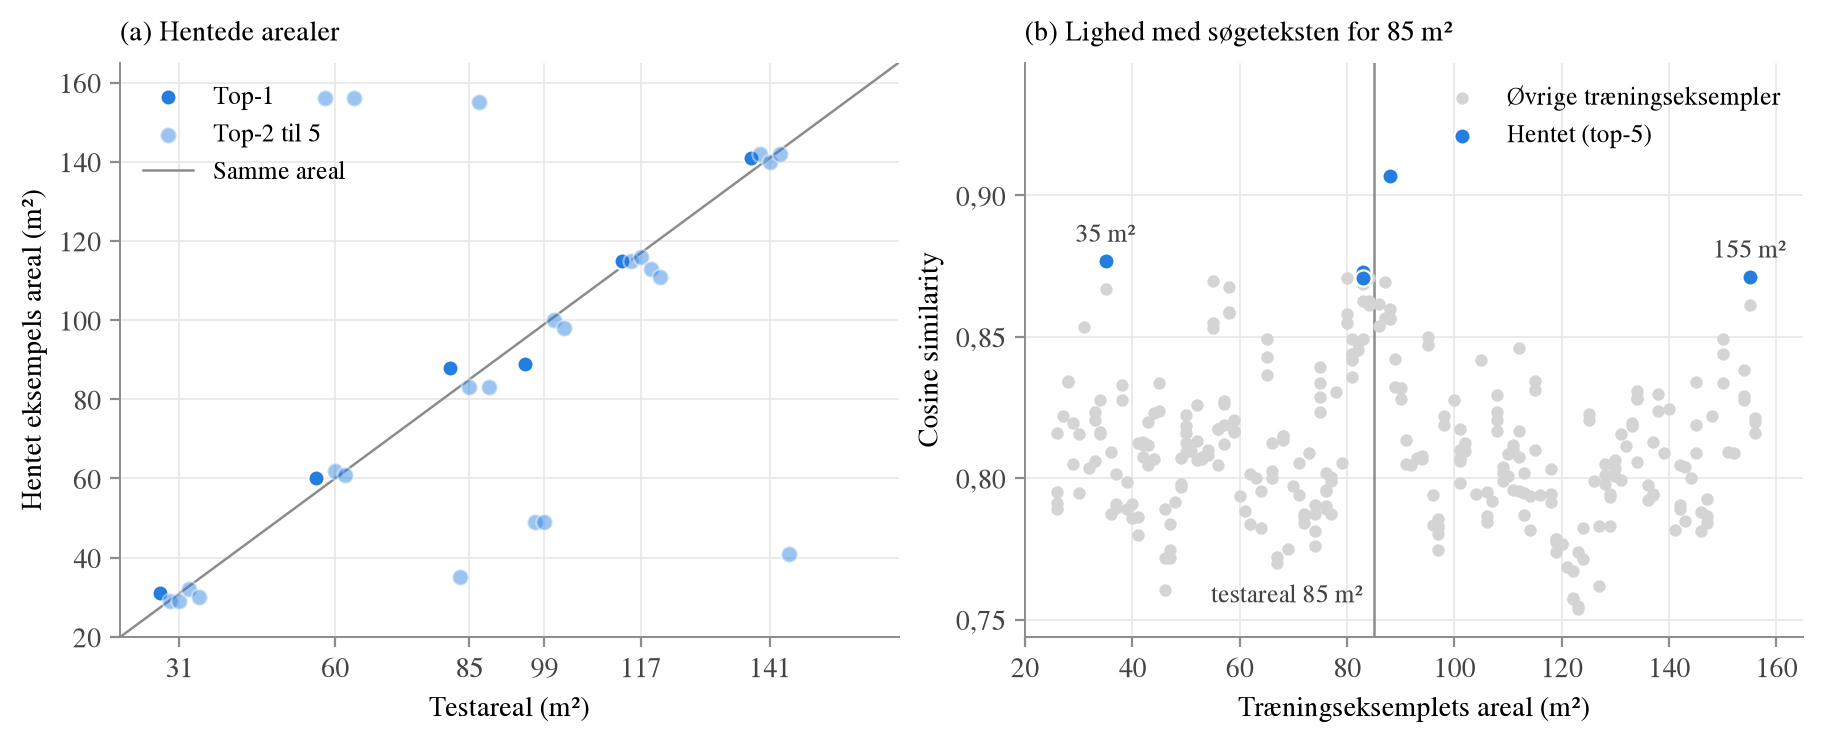

In [9]:
profile_area = "85"
profile = retrieve(DEFAULT_DATABASE, query_text(profile_area), len(train), OLLAMA_URL)

fig, (ax_a, ax_b) = plt.subplots(1, 2)

# (a) Hentet areal mod testareal. Rang 1–5 forskydes lidt vandret, så punkterne ikke dækker hinanden.
for ranks, label, alpha in [([1], "Top-1", 1.0), ([2, 3, 4, 5], "Top-2 til 5", 0.45)]:
    xs, ys = [], []
    for area in test_areas:
        for rank, (_, chunk_id, _) in enumerate(retrieved[area], start=1):
            if rank in ranks:
                xs.append(float(area) + (rank - 3) * 1.8)
                ys.append(float(train_by_id[chunk_id]["area_m2"]))
    ax_a.scatter(xs, ys, s=34, color=BLUE, alpha=alpha, edgecolors="white", linewidths=0.8,
                 label=label, zorder=3)
ax_a.plot([20, 165], [20, 165], color=GREY, linewidth=0.9, zorder=2, label="Samme areal")
ax_a.set(xlim=(20, 165), ylim=(20, 165), xticks=[float(area) for area in test_areas],
         xlabel="Testareal (m²)", ylabel="Hentet eksempels areal (m²)", title="(a) Hentede arealer")
ax_a.legend(loc="upper left")

# (b) Similarity for én testcase over alle træningseksempler.
all_areas = [float(train_by_id[chunk_id]["area_m2"]) for _, chunk_id, _ in profile]
all_sims = [similarity for similarity, _, _ in profile]
k = DEFAULT_TOP_K
ax_b.scatter(all_areas[k:], all_sims[k:], s=12, color=LIGHT, label="Øvrige træningseksempler", zorder=2)
ax_b.scatter(all_areas[:k], all_sims[:k], s=34, color=BLUE, edgecolors="white", linewidths=0.8,
             label=f"Hentet (top-{k})", zorder=3)
ax_b.axvline(float(profile_area), color=GREY, linewidth=0.9, zorder=1)
ax_b.annotate(f"testareal {profile_area} m²", (float(profile_area), min(all_sims)), xytext=(-4, 0),
              textcoords="offset points", fontsize=9, color="#444444", ha="right", va="bottom")
for area, similarity in zip(all_areas[:k], all_sims[:k]):
    if abs(area - float(profile_area)) > 20:
        ax_b.annotate(f"{area:g} m²", (area, similarity), xytext=(0, 7), textcoords="offset points",
                      fontsize=9, color="#444444", ha="center")
ax_b.yaxis.set_major_locator(MultipleLocator(0.05))
ax_b.yaxis.set_major_formatter(FuncFormatter(lambda value, _: dk(value, 2)))
ax_b.set(xlim=(20, 165), ylim=(min(all_sims) - 0.01, max(all_sims) + 0.04),
         xlabel="Træningseksemplets areal (m²)", ylabel="Cosine similarity",
         title=f"(b) Lighed med søgeteksten for {profile_area} m²")
ax_b.legend(loc="upper right")
plt.show()

**Figur 1.** (a) Areal på de fem hentede eksempler for hver testcase. Punkter på den grå linje har samme areal som testcasen. (b) Cosine similarity mellem søgeteksten for 85 m² og alle 294 træningseksempler. De fem hentede er fremhævet.

Ligheden falder ikke jævnt med afstanden i areal. I (b) ligger 35 og 155 m² på niveau med eksemplerne på 83 m², og hele spændet er kun ca. 0,75–0,91. Eksempelteksterne indeholder desuden lejebeløbet, som søgeteksten mangler, hvilket tilføjer støj. Embeddings er altså et svagt mål for numerisk nærhed.

### 4.3 Nøjagtighed

Først her læses testrækkernes faktiske husleje. Regressionens forudsigelser hentes fra `../regression/predictions_regression.csv` (kør `train_linear_regression.py`, hvis filen mangler). Fejlen er den absolutte afvigelse $|\hat{y} - y|$, og MAE er gennemsnittet over de seks testcases.

In [10]:
regression_dir = ROOT / "experiments" / "regression"
with (regression_dir / "dataset.csv").open(encoding="utf-8", newline="") as file:
    test = {row["area_m2"]: row for row in csv.DictReader(file) if row["split"] == "test"}
with (regression_dir / "predictions_regression.csv").open(encoding="utf-8", newline="") as file:
    regression = {row["area_m2"]: float(row["predicted_rent_dkk"]) for row in csv.DictReader(file)}

actual = {area: float(test[area]["monthly_rent_dkk"]) for area in test_areas}
methods = {"Regression": regression, "LLM + RAG": llm_rag, "LLM uden RAG": llm_plain}
errors = {
    name: {area: abs(predicted[area] - actual[area]) for area in test_areas}
    for name, predicted in methods.items()
}
mae = {name: sum(error.values()) / len(error) for name, error in errors.items()}

In [11]:
rows = []
for area in test_areas:
    best = min(errors[name][area] for name in methods)
    kind = "rigtig" if test[area]["data_type"] == "real" else "genereret"
    cells = [f"{area} m²", kind, dk(actual[area])]
    for name, predicted in methods.items():
        cell = f"{dk(predicted[area])} ({dk(errors[name][area])})"
        cells.append(f"**{cell}**" if errors[name][area] == best else cell)
    rows.append(cells)
rows.append(["**MAE**", "", ""] + [
    f"**{dk(mae[name])}**" if mae[name] == min(mae.values()) else dk(mae[name]) for name in methods
])

table(
    "**Tabel 5.** Faktisk og forudsagt månedlig husleje i kr. med absolut fejl i parentes. "
    "**Fed:** mindste fejl i rækken.",
    ["Testcase", "Type", "Faktisk", *methods],
    rows,
    "llrrrr",
)

**Tabel 5.** Faktisk og forudsagt månedlig husleje i kr. med absolut fejl i parentes. **Fed:** mindste fejl i rækken.

| Testcase | Type | Faktisk | Regression | LLM + RAG | LLM uden RAG |
|:---|:---|---:|---:|---:|---:|
| 31 m² | genereret | 9.300 | **9.178 (122)** | 8.400 (900) | 31 (9.269) |
| 60 m² | genereret | 13.600 | 13.210 (390) | **13.350 (250)** | 60 (13.540) |
| 85 m² | rigtig | 14.500 | **16.686 (2.186)** | 19.850 (5.350) | 85 (14.415) |
| 99 m² | genereret | 16.550 | **18.633 (2.083)** | 19.995 (3.445) | 99 (16.451) |
| 117 m² | rigtig | 20.486 | **21.136 (650)** | 18.800 (1.686) | 117 (20.369) |
| 141 m² | genereret | 24.900 | **24.473 (427)** | 23.700 (1.200) | 141 (24.759) |
| **MAE** |  |  | **976** | 2.138 | 16.467 |

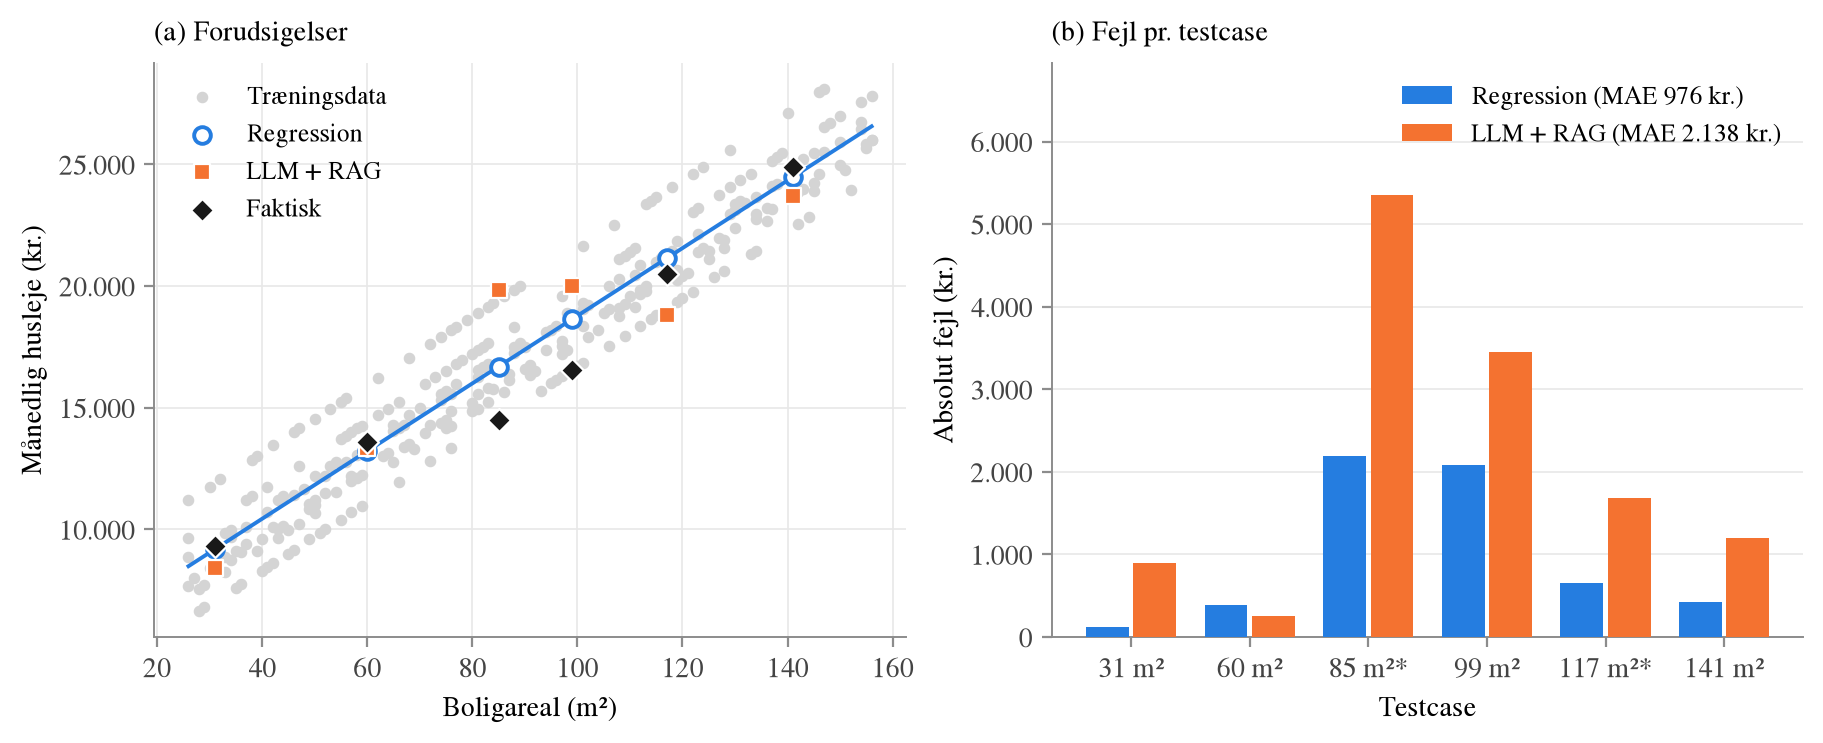

In [12]:
xs = [float(area) for area in test_areas]
fig, (ax_a, ax_b) = plt.subplots(1, 2)

# (a) Forudsigelser oven på træningsdata. Regressionens punkter ligger på én linje, som forlænges.
slope = (regression[test_areas[-1]] - regression[test_areas[0]]) / (xs[-1] - xs[0])
line_x = [min(train_areas), max(train_areas)]
line_y = [regression[test_areas[0]] + slope * (x - xs[0]) for x in line_x]
ax_a.scatter(train_areas, [float(row["monthly_rent_dkk"]) for row in train], s=10, color=LIGHT,
             label="Træningsdata", zorder=2)
ax_a.plot(line_x, line_y, color=BLUE, linewidth=1.4, zorder=3)
ax_a.scatter(xs, [regression[a] for a in test_areas], s=36, color="white", edgecolors=BLUE,
             linewidths=1.4, label="Regression", zorder=4)
ax_a.scatter(xs, [llm_rag[a] for a in test_areas], s=36, marker="s", color=ORANGE, edgecolors="white",
             linewidths=0.8, label="LLM + RAG", zorder=5)
ax_a.scatter(xs, [actual[a] for a in test_areas], s=34, marker="D", color=INK, edgecolors="white",
             linewidths=0.8, label="Faktisk", zorder=6)
ax_a.yaxis.set_major_formatter(FuncFormatter(lambda value, _: dk(value)))
ax_a.set(xlabel="Boligareal (m²)", ylabel="Månedlig husleje (kr.)", title="(a) Forudsigelser")
ax_a.legend(loc="upper left")

# (b) Absolut fejl pr. testcase, med et lille mellemrum mellem søjlerne.
positions = range(len(test_areas))
width = 0.36
for offset, name, color in [(-0.5, "Regression", BLUE), (0.5, "LLM + RAG", ORANGE)]:
    ax_b.bar([p + offset * (width + 0.04) for p in positions], [errors[name][a] for a in test_areas],
             width, color=color, label=f"{name} (MAE {dk(mae[name])} kr.)", zorder=3)
ax_b.set_xticks(list(positions),
                [f"{a} m²" + ("*" if test[a]["data_type"] == "real" else "") for a in test_areas])
ax_b.yaxis.set_major_formatter(FuncFormatter(lambda value, _: dk(value)))
ax_b.grid(axis="x", visible=False)
ax_b.set(ylim=(0, 1.3 * max(errors["LLM + RAG"].values())), xlabel="Testcase",
         ylabel="Absolut fejl (kr.)", title="(b) Fejl pr. testcase")
ax_b.legend(loc="upper right")
plt.show()

**Figur 2.** (a) Faktisk og forudsagt husleje for de seks testcases sammen med træningsdata. (b) Absolut fejl pr. testcase; * markerer rigtige annoncer. LLM uden RAG er udeladt, da dens svar (31–141 kr.) ligger langt uden for skalaen.

Regressionen har den mindste fejl i fem af seks testcases. LLM + RAG er kun bedre ved 60 m², hvor det præcise areal blev hentet som #1. Et præcist match er dog ingen garanti: ved 141 m² blev det også hentet som #1, men lejen for den ene lejlighed afveg 1.200 kr., mens regressionen, der udjævner over alle 294 rækker, ramte inden for 427 kr. Begge metoder overvurderer den rigtige annonce på 85 m², der ligger under den generelle tendens, men LLM + RAG forstærker fejlen ved at gentage lejen for et dyrt eksempel på 88 m².

## 5 Diskussion

**Regression mod opslag.** Regressionen estimerer én lineær sammenhæng ud fra alle 294 træningsrækker (ca. 139 kr. pr. m² plus 4.868 kr.) og udjævner dermed støjen i de enkelte annoncer. LLM + RAG ser kun fem rækker og gentager én af dem, så estimatet arver hele støjen fra det valgte eksempel. At de genererede rækker ser ud til at følge en lineær sammenhæng, giver regressionen en yderligere fordel.

**Retrieval er flaskehalsen.** Når modellen kopierer, er nøjagtigheden bestemt af retrieval, og embeddings måler tekstlighed frem for numerisk afstand. Hentning efter areal, fx de *k* nærmeste arealer eller et filter på metadata, og en større model, der kan ræsonnere over eksemplerne, er de oplagte forbedringer.

**Anvendelse.** Ved numerisk input med en stabil sammenhæng er en specialiseret model at foretrække. Den er mere præcis, kan forklares med to parametre og svarer på mikrosekunder frem for sekunder. LLM + RAG er mere relevant ved ustruktureret input som annoncetekster, når svaret skal begrundes i naturligt sprog, eller når der er få eksempler, men meget baggrundsviden.

**Begrænsninger.** Seks testcases giver en usikker MAE, og 290 af 300 rækker er genererede. Modellen er meget lille, og kun én prompt og ét input er afprøvet. Beliggenhed, antal værelser og stand indgår ikke.

## 6 Konklusion

RAG gør det muligt for en lille lokal LLM at give realistiske huslejeestimater, hvor den uden eksempler slet ikke rammer skalaen. Den er dog mindre præcis end lineær regression (MAE 2.138 mod 976 kr.), fordi den fungerer som et opslag i de hentede eksempler og ikke som en model af sammenhængen. Den fulde log med prompts og rå svar står i [`retrieval_log.md`](retrieval_log.md), og den samlede diskussion i [`../README.md`](../README.md).